# 10 · ROOT C++ macros and FastJet in C++

**Time:** 45 minutes · **Needs:** ROOT ≥ 6.34 (C++); FastJet's C++ library for section 7 · **Data:** `auau_stats` and `pp_ref`: the ROOT files (0.25 GB, downloaded once)

Tutorial 09 read the ROOT files of `run_h5toROOT.py` from Python. Most analyses in the
field are C++ programs and ROOT macros, so this tutorial does the same in C++. It writes
small macros, compiles them with ACLiC and runs them from the notebook:
- `HadronFileReader.h`, the header-only C++ reader: an event's hadrons as vectors;
- a loop over events and samples that fills histograms with the right normalisation;
- the macros that come with js-contrib, `read_hadrons.C` and `hadron_distributions.C`;
- RDataFrame in C++ on the RNTuples, checked against the reader;
- anti-$k_T$ jets with FastJet's C++ library, with the background subtracted.

The data are those of tutorial 09: 120 Au+Au events (0–10 %, 200 GeV) in three p̂T windows,
and their p+p reference.

Reference pages: [ROOT and C++](https://jhputschke.github.io/js-contrib/analysis/root/),
[Jets with FastJet](https://jhputschke.github.io/js-contrib/analysis/jets/).

> **The outputs shown** were produced on an Apple Silicon Mac, in the environment the xscape wheel 0.2.0 is built in, with the hydro on the GPU through Metal. ROOT 6.36 and FastJet 3.4.3 (C++) came from Homebrew.

In [1]:
# Setup: the tutorial helpers sit next to this notebook (_common/).
import os, sys
sys.path.insert(0, os.getcwd())
from _common import tutorial_env as te
env = te.setup()

tutorials v1.dev | setup: source (runs X-SCAPE; hydro: Metal GPU) | Python 3.13.1 | data: data/


In [2]:
ok, missing = te.meets(['root'], env.caps)
assert ok, f"this tutorial needs {missing}: see 01_check_setup.ipynb"

## 1. ROOT from a Python notebook

This is a Python notebook: Jupyter has no C++ kernel here. (ROOT has its own, `root
--notebook`; the C++ notebook `read_hadrons.ipynb` in js-contrib uses it.) Instead, each
macro is written to a file with `%%writefile`, and ROOT runs it in batch mode, the way it
runs on a cluster: `root -l -b -q 'macro.C+(arguments)'`.

| option | |
|---|---|
| `-l` | no splash screen |
| `-b` | batch: no graphics windows (figures are saved as files) |
| `-q` | quit when the macro is done |
| `macro.C+` | compile the macro with **ACLiC** (the system compiler) instead of interpreting it with Cling: full C++ speed and compiler errors before anything runs |

First, which ROOT is there? The ROOT files are RNTuples, which need ROOT 6.34 or later:

In [3]:
import re
import subprocess

def sh(*cmd):
    return subprocess.run(cmd, capture_output=True, text=True, check=True).stdout.strip()

version = sh("root-config", "--version")
features = sh("root-config", "--features").split()
print("ROOT", version, "| RDataFrame:", "dataframe" in features, "| multithreading:", "imt" in features)
major, minor = (int(x) for x in re.split(r"[./]", version)[:2])
assert (major, minor) >= (6, 34), "RNTuple needs ROOT >= 6.34 (or convert with run_h5toROOT.py --format ttree)"

ROOT 6.36.06 | RDataFrame: True | multithreading: True


A shell command works too, with `!`:

In [4]:
!root -l -b -q -e 'std::cout << "hello from ROOT " << gROOT->GetVersion() << std::endl;'


hello from ROOT 6.36.06


For the macros we use a small helper, `root()`. It runs one macro call in batch mode in the
folder `out/10_root_cpp/`, where the macros and their outputs go, adds include paths and
libraries first, prints ROOT's output (with the paths shortened), and raises an error when
ROOT fails. A macro call that compiles and returns gives exit code 0; a compiler error or an
uncaught C++ exception gives another code.

In [5]:
import os
import time
from pathlib import Path
from IPython.display import Image, display

HERE = Path.cwd()
OUT = Path("out/10_root_cpp")                       # macros and outputs (out/ is git-ignored)
OUT.mkdir(parents=True, exist_ok=True)

def root(call, includes=(), libraries=()):
    """Run ROOT in batch on one macro call; print its output; raise if it fails."""
    setup = "".join(f'gSystem->AddIncludePath("-I{Path(p).resolve()}");' for p in includes)
    setup += "".join(f'gSystem->Load("{lib}");' for lib in libraries)
    cmd = ["root", "-l", "-b", "-q"] + (["-e", setup] if setup else []) + [call]
    t0 = time.time()
    p = subprocess.run(cmd, cwd=OUT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in p.stdout.splitlines():
        if not line.strip() or line.startswith("#"):          # (FastJet's banner)
            continue
        if "ACLiC>: creating shared library" in line:
            line = "ACLiC: compiled " + os.path.relpath(line.split()[-1], OUT)
        print(te.short(line.replace(str(OUT.resolve()) + "/", "")))
    if p.returncode != 0:
        raise RuntimeError(f"ROOT failed (exit code {p.returncode})")
    print(f"[{time.time() - t0:.0f} s]")

## 2. The files and the reader

The macros read files on disk, so we download the ROOT files of both sets once (the hadron
HDF5 files are not needed). ROOT runs in `out/10_root_cpp/`, so the paths are given relative
to that folder:

In [6]:
AUAU = os.path.relpath(te.fetch("auau_stats", include=["*_hadrons.root", "stats_campaign.root"], quiet=True), OUT)
PP = os.path.relpath(te.fetch("pp_ref", include=["*_hadrons.root", "ppref_campaign.root"], quiet=True), OUT)
print("Au+Au:", AUAU, "| p+p:", PP)

Au+Au: ../../data/auau_stats | p+p: ../../data/pp_ref


`HadronFileReader.h` and the example macros live in js-contrib, in
`contribs/PyJetscape/example/analysis_root/`. We copy the ones we need next to our macros:
from your js-contrib (a checkout or the installed tree), or else from GitHub. Copies, because
ACLiC writes its compiled library next to the macro, and an installed tree may be read-only.

In [7]:
import shutil
import urllib.request

ANALYSIS_ROOT = ("https://raw.githubusercontent.com/jhputschke/js-contrib/main/"
                 "contribs/PyJetscape/example/analysis_root/")

def analysis_root_file(name):
    """Copy analysis_root/<name> into OUT: from the local js-contrib, else from GitHub."""
    try:
        from jetscape import paths
        src = Path(paths.examples_dir()) / "analysis_root" / name
    except Exception:
        src = None
    if src is not None and src.is_file():
        shutil.copy(src, OUT / name)
        return "js-contrib"
    urllib.request.urlretrieve(ANALYSIS_ROOT + name, OUT / name)
    return "GitHub"

for name in ["HadronFileReader.h", "read_hadrons.C", "hadron_distributions.C"]:
    print(f"{name:24s} from", analysis_root_file(name))

HadronFileReader.h       from js-contrib
read_hadrons.C           from js-contrib
hadron_distributions.C   from js-contrib


`HadronFileReader.h` is the C++ counterpart of the Python `HadronFileReader` of tutorial 07.
It reads all `*_hadrons.root` files of a directory (and the campaign file), numbers the events
over all files, and returns the hadrons of one sample of one event as a
`std::vector<Hadron>`:

| call | ntuple | the hadrons of |
|---|---|---|
| `r.bkg(e, k)` | `bulk_bg` | sample k of the background of event e (MUSIC_1, no jet) |
| `r.bkg_dep(e, k)` | `bulk_jet` | oversample k of the jet leg: background + the jet's deposition (MUSIC_2) |
| `r.frag(e, j)` | `jet_frag` | fragmentation j of the jet's partons |
| `r.bkg_dep_frag(e, k)` | both | the whole jet event: `bkg_dep(e, k)` + fragmentation k mod `n_frag(e)` |

A `Hadron` has `pid`, `E`, `px`, `py`, `pz` and `pt()`, `eta()`, `phi()`, `charged()`, `p4()`.
`r.info(e)` is the event's row of the `events` table (`EventInfo`: window, background,
initiators, sample counts, `flagged()`).

## 3. A first macro, compiled with ACLiC

The macro opens the campaign, prints the windows and their cross sections, and looks at
one event: its record and the hadrons of its first sample from each source.

In [8]:
%%writefile out/10_root_cpp/first_look.C
// first_look.C: open a campaign with HadronFileReader.h and look at one event
#include "HadronFileReader.h"

#include <cmath>
#include <cstdio>

void first_look(const char *dir, long e = 0) {
  using namespace hadrons_root;
  HadronFileReader r(dir);                       // every *_hadrons.root + the campaign file
  std::printf("%d files, %ld events; cross sections from the %s\n", r.n_files(),
              r.n_events(), r.sigma_source().c_str());
  for (int k = 0; k < r.n_windows(); ++k)
    std::printf("  window %d: pTHat %2.0f-%2.0f GeV, sigma = %.3e mb, %ld events,"
                " weight_mb = %.3e mb\n", k, r.pthat_lo(k), r.pthat_hi(k), r.sigma_mb(k),
                r.n_window_events(k), r.weight_mb(k));

  const EventInfo &info = r.info(e);             // the event's row of the events table
  const Initiator *lead = info.leading();        // its hardest shower initiator
  std::printf("event %ld: file %d (event %d there), window %d, pTHat %.1f GeV, background %d,"
              " vacuum %s, flagged %s\n", e, info.file_index, info.local_event,
              info.pthat_bin, info.pthat, info.bg_unit, info.vacuum ? "yes" : "no",
              info.flagged() ? "yes" : "no");
  std::printf("  %zu shower initiators; the leading one: pT %.1f GeV, eta %.2f, phi %.2f\n",
              info.initiators.size(), lead->pt(), lead->eta(), lead->phi());
  std::printf("  samples: jet leg %d, background %d, fragmentations %d\n",
              r.n_oversamples(e), r.n_bg_samples(e), r.n_frag(e));

  // the hadrons of sample 0 of each source, as std::vector<Hadron>
  auto count = [](const Hadrons &hs) {
    int n = 0;
    for (const Hadron &h : hs) n += h.charged() && std::fabs(h.eta()) < 1;
    return n;
  };
  std::printf("  sample 0:          all hadrons   charged, |eta| < 1\n");
  const Hadrons frag = r.frag(e, 0);
  std::printf("    frag            %9zu   %9d\n", frag.size(), count(frag));
  if (info.vacuum) return;                       // p+p: no medium, no bulk
  const Hadrons bkg = r.bkg(e, 0), dep = r.bkg_dep(e, 0), full = r.bkg_dep_frag(e, 0);
  std::printf("    bkg             %9zu   %9d\n", bkg.size(), count(bkg));
  std::printf("    bkg_dep         %9zu   %9d\n", dep.size(), count(dep));
  std::printf("    bkg_dep_frag    %9zu   %9d\n", full.size(), count(full));
}

Writing out/10_root_cpp/first_look.C


In [9]:
root(f'first_look.C+("{AUAU}")', includes=[OUT])

Processing first_look.C+("../../data/auau_stats")...
ACLiC: compiled first_look_C.so
4 files, 120 events; cross sections from the campaign file ../../data/auau_stats/stats_campaign.root
  window 0: pTHat 10-20 GeV, sigma = 2.853e-03 mb, 40 events, weight_mb = 7.131e-05 mb
  window 1: pTHat 20-30 GeV, sigma = 3.731e-05 mb, 40 events, weight_mb = 9.327e-07 mb
  window 2: pTHat 30-50 GeV, sigma = 2.570e-06 mb, 40 events, weight_mb = 6.425e-08 mb
event 0: file 0 (event 0 there), window 0, pTHat 12.1 GeV, background 0, vacuum no, flagged no
  4 shower initiators; the leading one: pT 13.4 GeV, eta 0.54, phi 2.81
  samples: jet leg 10, background 20, fragmentations 10
  sample 0:          all hadrons   charged, |eta| < 1
    frag                   20           2
    bkg                  8673        1533
    bkg_dep              8819        1452
    bkg_dep_frag         8839        1454
[12 s]


**What to notice.**

- **The cross sections** are the campaign file's, as in tutorial 09; `weight_mb` is
  σ_k / N_k, the weight of one event of window k.
- **Event 0** is a 10–20 GeV jet (p̂T = 12.1 GeV) in background 0. Its leading parton has
  13.4 GeV, and its fragmentation 0 has only 20 hadrons, 2 of them charged at
  $|\eta| < 1$: the event's droplets carried 26 GeV into the fluid (`E_droplets` in
  tutorial 09's events table).
- **Sample 0 of the jet leg has fewer** charged hadrons at midrapidity (1,452) than sample 0
  of the background (1,533), although the jet added energy. Single samples fluctuate by about
  ±43 (tutorial 09), and these files were sampled independently. Only averages over many
  samples show what the jet did.

ACLiC compiled the macro into a shared library next to it, with a few helper files:

In [10]:
print(sorted(p.name for p in OUT.glob("first_look*")))
root(f'first_look.C+("{PP}")', includes=[OUT])          # unchanged: not compiled again

['first_look.C', 'first_look_C.d', 'first_look_C.so', 'first_look_C_ACLiC_dict_rdict.pcm']


Processing first_look.C+("../../data/pp_ref")...
3 files, 4500 events; cross sections from the campaign file ../../data/pp_ref/ppref_campaign.root
  window 0: pTHat 10-20 GeV, sigma = 2.290e-03 mb, 1500 events, weight_mb = 1.527e-06 mb
  window 1: pTHat 20-30 GeV, sigma = 4.244e-05 mb, 1500 events, weight_mb = 2.830e-08 mb
  window 2: pTHat 30-50 GeV, sigma = 2.198e-06 mb, 1500 events, weight_mb = 1.465e-09 mb
event 0: file 0 (event 0 there), window 0, pTHat 13.0 GeV, background -1, vacuum yes, flagged no
  6 shower initiators; the leading one: pT 13.4 GeV, eta -0.33, phi 2.51
  samples: jet leg 0, background 0, fragmentations 10
  sample 0:          all hadrons   charged, |eta| < 1
    frag                   72          18
[1 s]


- `first_look_C.so` is the compiled macro, `first_look_C.d` its dependencies (to know when to
  recompile), `first_look_C_ACLiC_dict_rdict.pcm` ROOT's dictionary for it. js-contrib's
  `.gitignore` ignores all of them (`*.so`, `*_C.d`, `*.pcm`). `.C+` recompiles only when the
  macro or a header it includes has changed; `.C++` always recompiles.
- The second call reused the library, so it took a second instead of the compilation.
- **The p+p files** have no bulk: `vacuum` is set, every event has only its 10
  fragmentations, and the macro returned before asking for a background. On a vacuum file
  `r.bkg(e, k)` throws a `std::runtime_error`, which ends ROOT with an error.

## 4. Loop over events and samples, with the right normalisation

The core of every analysis of these files is one loop. The rules (tutorial 09, and the
reader's README):
- **Each event is the mean over its own samples.** A hadron of oversample k of event e
  weighs $w_e / n$, with n the number of samples of that source for that event.
- **Each event weighs** $w_e = \sigma_k / N_k$ (mb) for a cross-section-weighted result over
  the windows, or $w_e = 1/N$ for a result per event.
- **A background serves several events** (here 6). It counts once for each of them. The macro
  reads it once and gives it the sum of its events' weights; filling it once per event would
  give the same values but too small errors, since the same hadrons would enter as
  independent fills.

The macro fills the $p_T$ spectra of charged hadrons at $|\eta| < 1$ for each source, and the
jet fragments of each window separately. It writes the histograms to a ROOT file and draws
them into a PNG:

In [11]:
%%writefile out/10_root_cpp/spectra.C
// spectra.C: cross-section-weighted pT spectra of charged hadrons at |eta| < 1, per source,
// with HadronFileReader.h.  Every event is the mean over its own samples: a hadron of event
// e weighs w_e / n_samples, with w_e = sigma_k / N_k of its pTHat window k [mb], or 1 / N.
#include "HadronFileReader.h"

#include <TCanvas.h>
#include <TFile.h>
#include <TH1D.h>
#include <TLegend.h>
#include <TStopwatch.h>
#include <TStyle.h>

#include <cmath>
#include <cstdio>
#include <map>
#include <utility>
#include <vector>

void spectra(const char *dir, const char *out, bool xsec = true) {
  using namespace hadrons_root;
  TStopwatch clock;
  HadronFileReader r(dir);
  r.set_charged_eta(1.0);                        // keep charged hadrons at |eta| < 1 only

  // 24 logarithmic pT bins from 0.2 to 50 GeV (those of tutorial 09)
  const int nb = 24;
  std::vector<double> edges(nb + 1);
  for (int i = 0; i <= nb; ++i) edges[i] = 0.2 * std::pow(50 / 0.2, double(i) / nb);
  auto book = [&](const char *name, const char *title) {
    auto *h = new TH1D(name, title, nb, edges.data());
    h->SetDirectory(nullptr);
    h->Sumw2();                                  // errors from the sum of squared weights
    return h;
  };
  TH1D *h_bkg = book("h_bkg", "background (bulk_bg)");
  TH1D *h_dep = book("h_bkgdep", "background + deposition (bulk_jet)");
  TH1D *h_frag = book("h_frag", "jet fragments (jet_frag)");
  TH1D *h_full = book("h_full", "the jet event (bulk_jet + jet_frag)");
  std::vector<TH1D *> h_win;                     // the jet fragments of each pTHat window
  for (int k = 0; k < r.n_windows(); ++k)
    h_win.push_back(book(Form("h_frag_w%d", k), Form("jet fragments, window %d", k)));

  // the event weights: sigma_k / N_k [mb], or 1 / N [per event]
  const std::vector<long> events = r.select_events();      // hadronized, not flagged
  std::map<int, long> n_window;
  for (long e : events) ++n_window[r.info(e).pthat_bin];
  auto weight = [&](long e) {
    const int k = r.info(e).pthat_bin;
    return xsec ? r.sigma_mb(k) / n_window[k] : 1.0 / events.size();
  };
  auto fill = [](TH1D *h, const Hadrons &hs, double w) {
    for (const Hadron &x : hs) h->Fill(x.pt(), w);
  };

  // the backgrounds: read once per (file, background), weighted with the sum of the weights
  // of the events using it -- it counts once for each of them, and its errors come out right
  std::map<std::pair<int, int>, std::pair<long, double>> backgrounds;   // -> (an event, sum w)
  for (long e : events) {
    const EventInfo &info = r.info(e);
    if (info.vacuum) continue;                   // p+p: no medium
    auto &b = backgrounds[{info.file_index, info.bg_unit}];
    if (b.second == 0) b.first = e;
    b.second += weight(e);
  }
  for (const auto &[key, b] : backgrounds) {
    const int n = r.n_bg_samples(b.first);
    for (int k = 0; k < n; ++k) fill(h_bkg, r.bkg(b.first, k), b.second / n);
  }

  // the jet events: the jet leg's oversamples, and the fragmentations
  for (long e : events) {
    const double w = weight(e);
    const int nj = r.n_oversamples(e), nf = r.n_frag(e);
    for (int k = 0; k < nj; ++k) fill(h_dep, r.bkg_dep(e, k), w / nj);
    for (int j = 0; j < nf; ++j) {
      const Hadrons frag = r.frag(e, j);
      fill(h_frag, frag, w / nf);
      if (xsec) fill(h_win[r.info(e).pthat_bin], frag, w / nf);
    }
  }
  h_full->Add(h_dep, h_frag);                    // the jet event = bkg_dep + frag
  for (TH1D *h : {h_bkg, h_dep, h_frag, h_full}) h->Scale(1.0, "width");   // -> per GeV
  for (TH1D *h : h_win) h->Scale(1.0, "width");

  std::printf("%zu events, %zu backgrounds; integrals [%s]:\n", events.size(),
              backgrounds.size(), xsec ? "mb" : "per event");
  for (TH1D *h : {h_bkg, h_dep, h_frag, h_full})
    std::printf("  %-8s %10.4g\n", h->GetName() + 2, h->Integral("width"));

  // the figure: the spectra, and the windows' contributions to the jet fragments
  gStyle->SetOptStat(0);
  TCanvas c("c", "", 1100, 450);
  c.Divide(2, 1);
  c.cd(1);
  gPad->SetLogx();
  gPad->SetLogy();
  TLegend leg(0.15, 0.15, 0.40, 0.40);
  const std::vector<std::pair<TH1D *, int>> style = {
      {h_full, kBlack}, {h_dep, kRed + 1}, {h_bkg, kBlue + 1}, {h_frag, kOrange + 1}};
  for (const auto &[h, color] : style) {
    h->SetLineColor(color);
    h->SetLineWidth(2);
    h->SetTitle(";p_{T} [GeV]");
    h->GetYaxis()->SetTitle(xsec ? "d#sigma/dp_{T} [mb/GeV]" : "dN/dp_{T} per event [1/GeV]");
    h->Draw(h == h_full ? "hist e" : "hist e same");
    leg.AddEntry(h, h->GetName() + 2, "l");
  }
  leg.SetBorderSize(0);
  leg.Draw();
  c.cd(2);
  gPad->SetLogx();
  gPad->SetLogy();
  TLegend leg2(0.55, 0.70, 0.89, 0.89);
  h_frag->Draw("hist e");
  leg2.AddEntry(h_frag, "jet fragments, sum", "l");
  const int wcolor[] = {kGreen + 2, kAzure + 1, kMagenta + 1};
  for (int k = 0; k < (xsec ? r.n_windows() : 0); ++k) {
    h_win[k]->SetLineColor(wcolor[k % 3]);
    h_win[k]->SetLineStyle(2);
    h_win[k]->Draw("hist same");
    leg2.AddEntry(h_win[k], Form("#hat{p}_{T} %.0f-%.0f GeV", r.pthat_lo(k), r.pthat_hi(k)), "l");
  }
  leg2.SetBorderSize(0);
  leg2.Draw();
  c.SaveAs(Form("%s.png", out));

  TFile f(Form("%s.root", out), "RECREATE");
  for (TH1D *h : {h_bkg, h_dep, h_frag, h_full}) h->Write();
  for (TH1D *h : h_win) h->Write();
  std::printf("-> %s.root, %s.png (%.1f s)\n", out, out, clock.RealTime());
}

Writing out/10_root_cpp/spectra.C


Processing spectra.C+("../../data/auau_stats", "spectra_auau")...
ACLiC: compiled spectra_C.so
120 events, 20 backgrounds; integrals [mb]:
  bkg           3.553
  bkgdep        3.573
  frag        0.01132
  full          3.584
Info in <TCanvas::Print>: png file spectra_auau.png has been created
-> spectra_auau.root, spectra_auau.png (0.6 s)
[13 s]


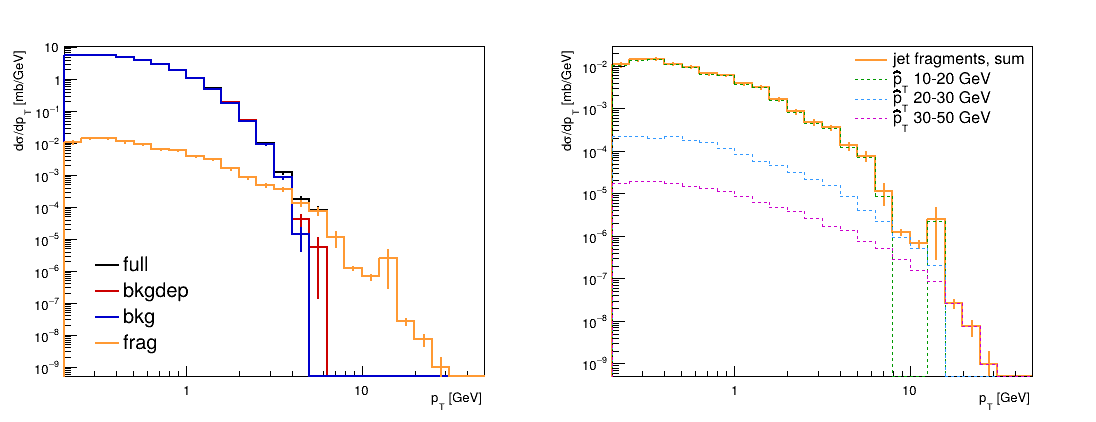

In [12]:
root(f'spectra.C+("{AUAU}", "spectra_auau")', includes=[OUT])
display(Image(filename=OUT / "spectra_auau.png"))

**What to notice.**

- **Left:** the bulk (`bkg`, `bkgdep`) dominates the jet event (`full`) up to 4 GeV, the jet's
  fragments (`frag`) above. The bulk ends near 6 GeV: the fluid makes no harder hadrons.
- **Right: how the windows add up.** Up to about 8 GeV, the 10–20 GeV window (with by far the
  largest cross section) gives almost all fragments. Above, its jets have no more energy to
  give, and the harder windows take over, each at its own range of $p_T$. That is why
  campaigns are generated in windows: the rare hard jets get the same number of events as the
  common soft ones, and the cross sections put each in its place.
- **The integrals** are $\sigma \times \langle N_{ch} \rangle$ in mb, for
  $0.2 < p_T < 50$ GeV.

The fragments' spectrum is the one tutorial 09 made in Python with uproot and `hist`, from
the same files. ROOT histograms read with uproot, so we compare bin by bin with tutorial 09's
stored result:

In [13]:
import json
import numpy as np
import uproot

with uproot.open(OUT / "spectra_auau.root") as rf:
    h_cpp = {name: rf[name].to_hist() for name in ["h_bkg", "h_bkgdep", "h_frag", "h_full"]}
widths = np.diff(h_cpp["h_frag"].axes[0].edges)
py09 = np.array(json.load(open("expected/09_root_from_python.json"))["dsigma_aa_frag"]) / widths
nz = py09 > 0
print("largest relative difference C++ reader vs tutorial 09 (uproot):",
      f"{np.max(np.abs(h_cpp['h_frag'].values() - py09)[nz] / py09[nz]):.1e};",
      "empty bins alike:", np.array_equal(h_cpp["h_frag"].values() == 0, ~nz))
np.testing.assert_allclose(h_cpp["h_frag"].values(), py09, rtol=1e-9)

largest relative difference C++ reader vs tutorial 09 (uproot): 0.0e+00; empty bins alike: True


## 5. The macros that come with js-contrib

`analysis_root/` has two complete macros, documented in its `README.md`:

- **`read_hadrons.C`** is the reader by example, a larger `spectra.C`: per source the $p_T$
  spectrum and the azimuth $\Delta\phi$ to the event's leading initiator, and the wake
  (`bkgdep − bkg`). `read_hadrons.ipynb` is the same macro in ROOT's C++ notebook kernel, one
  step per cell (it needs `pip install metakernel` in the ROOT environment).
- **`hadron_distributions.C`** fills $\eta$, $\phi$ and $p_T$ of every source and of the wake
  with RDataFrame, on several threads, and draws them on one page.

Their arguments are listed at the top of each file. Both run on our campaign as they are,
cross-section weighted (`xsec = true`):

In [14]:
root(f'read_hadrons.C+("{AUAU}", -1, true, 1.0, "read_hadrons_auau.root")', includes=[OUT])

Processing read_hadrons.C+("../../data/auau_stats", -1, true, 1.0, "read_hadrons_auau.root")...
ACLiC: compiled read_hadrons_C.so
read_hadrons: 120 event(s), charged hadrons, |#eta| < 1:
  bkg     N =      3.993   (mb)
  bkgdep  N =      4.016   (mb)
  frag    N =    0.01222   (mb)
  full    N =      4.029   (mb)
  wake    N =    0.02299   (mb)
read_hadrons: histograms -> read_hadrons_auau.root (1.1 s)
[15 s]


Processing hadron_distributions.C+("../../data/auau_stats", -1, true, true, 1.0, "hadron_distributions_auau.root", 4)...
ACLiC: compiled hadron_distributions_C.so
hadron_distributions: cross sections from ../../data/auau_stats/stats_campaign.root: 0.002853 3.731e-05 2.57e-06 mb
  AuAu_0_10_jet_stats_seed0201_hadrons.root: 30 event(s)
  AuAu_0_10_jet_stats_seed0202_hadrons.root: 30 event(s)
  AuAu_0_10_jet_stats_seed0203_hadrons.root: 30 event(s)
  AuAu_0_10_jet_stats_seed0204_hadrons.root: 30 event(s)
hadron_distributions: 120 event(s), 0 flagged and left out; charged hadrons, |eta| < 1:
  bkg     N =       4.11   (mb)
  bkgdep  N =      4.131
  frag    N =    0.01243
  wake    N =    0.02111
Info in <TCanvas::Print>: png file hadron_distributions_auau.png has been created
Info in <TCanvas::Print>: pdf file hadron_distributions_auau.pdf has been created
hadron_distributions: histograms -> hadron_distributions_auau.root, plots -> hadron_distributions_auau.pdf (and .png)
[18 s]


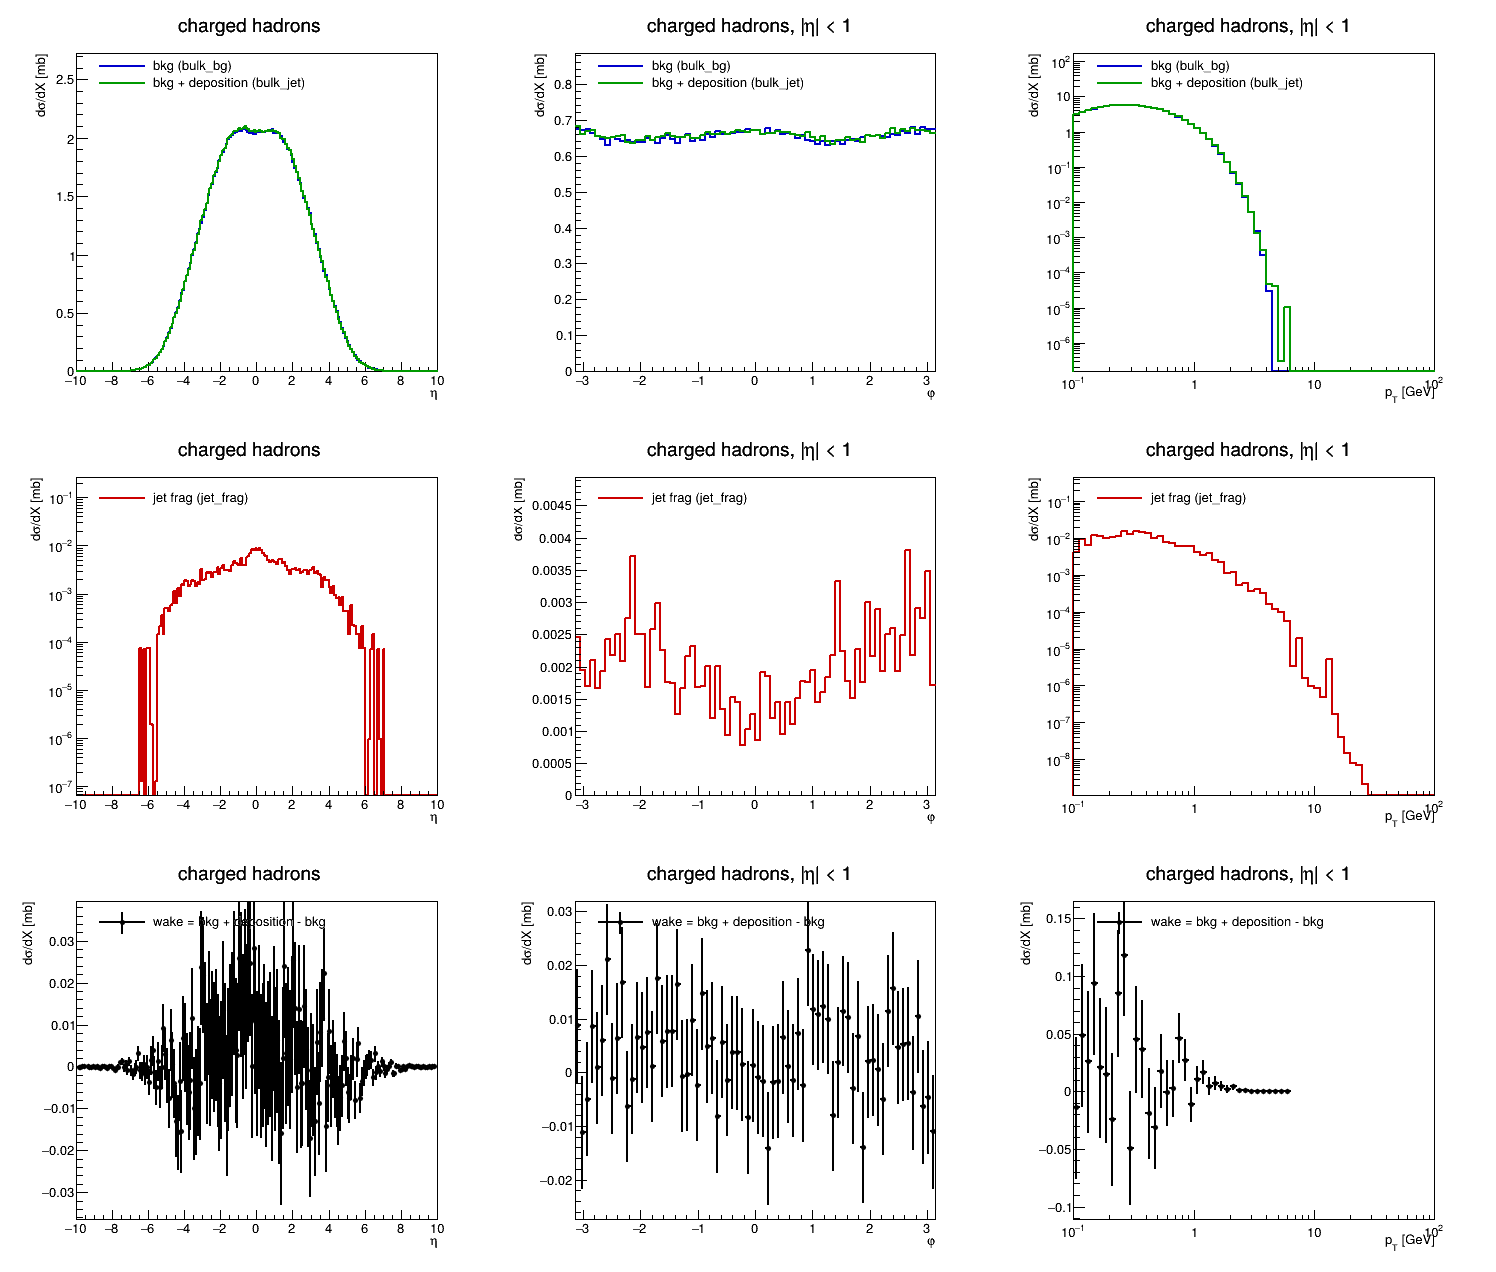

In [15]:
root(f'hadron_distributions.C+("{AUAU}", -1, true, true, 1.0, "hadron_distributions_auau.root", 4)',
     includes=[OUT])
display(Image(filename=OUT / "hadron_distributions_auau.png", width=900))

**What to notice.**

- **Rows:** background and background + deposition (top), the jet fragments (middle), and the
  wake, their difference (bottom); **columns:** $\eta$ (all $p_T$), $\phi$ and $p_T$ (at
  $|\eta| < 1$).
- **The wake is buried in noise here.** It is about 0.5 % of the bulk (0.021 of 4.1 mb), and
  these files were sampled independently, so each sample's ±43 hadrons enter the difference.
  Tutorial 07 measured the wake from files with correlated sampling, where that noise cancels.
- **The jet fragments reach $|\eta| \approx 6$–7**, far beyond the jets' partons at
  $|y| < 0.6$: the hadronization's strings stretch to the beam remnants. In $\phi$ (the lab
  frame, where jets point anywhere) they are not flat: with 120 events, a few jets make the
  shape.
- **The yields differ slightly** between the two macros (4.11 against 3.99 mb for `bkg`):
  `read_hadrons.C` counts the hadrons in its $p_T$ histogram (0.1–100 GeV), while
  `hadron_distributions.C` counts all $p_T$ at $|\eta| < 1$, including the few below 0.1 GeV.

## 6. RDataFrame in C++

`HadronFileReader.h` assembles events. When an analysis needs no events, only hadrons with
weights, RDataFrame reads the ntuples directly. It declares the analysis as columns
(`Define`) and results (`Histo1D`), then runs one loop over the data, in parallel on several
threads with `ROOT::EnableImplicitMT`. The same code reads RNTuples (ROOT ≥ 6.34) and TTrees.

The weight of an entry is that of its event: `weight_mb` of its window from the campaign file,
over the event's number of samples from the file's `events` table. This macro is the C++
form of tutorial 09's `xsec_spectrum`:

In [16]:
%%writefile out/10_root_cpp/rdf_spectrum.C
// rdf_spectrum.C: the cross-section-weighted pT spectrum of charged hadrons at |eta| < 1 of
// one hadron ntuple, with RDataFrame and no reader: an entry (one sample of an event) weighs
// weight_mb[window] / n_samples of its event.
#include <ROOT/RDataFrame.hxx>
#include <ROOT/RVec.hxx>
#include <TFile.h>
#include <TH1D.h>
#include <TStopwatch.h>

#include <algorithm>
#include <cmath>
#include <cstdio>
#include <filesystem>
#include <string>
#include <vector>

using ROOT::RVecI;

void rdf_spectrum(const char *dir, const char *campaign, const char *tag, const char *n_col,
                  const char *out, int threads = 1) {
  TStopwatch clock;
  if (threads > 1) ROOT::EnableImplicitMT(threads);

  // the campaign's weight per pTHat window: sigma_k / N_k [mb per event]
  const auto weight_mb = *ROOT::RDataFrame("windows", campaign).Take<double>("weight_mb");

  // the production files, sorted by name
  std::vector<std::string> files;
  for (const auto &p : std::filesystem::directory_iterator(dir)) {
    const std::string name = p.path().string();
    if (name.size() > 13 && name.compare(name.size() - 13, 13, "_hadrons.root") == 0)
      files.push_back(name);
  }
  std::sort(files.begin(), files.end());

  const int nb = 24;                             // the bins of spectra.C
  std::vector<double> edges(nb + 1);
  for (int i = 0; i <= nb; ++i) edges[i] = 0.2 * std::pow(50 / 0.2, double(i) / nb);
  TH1D total(Form("h_%s", tag), ";p_{T} [GeV];d#sigma/dp_{T} [mb/GeV]", nb, edges.data());
  total.Sumw2();

  // charged: pi, K, p, Sigma+-, Xi, Omega, e, mu (jetscape.hadrons_h5.CHARGED)
  auto charged = [](const RVecI &pid) {
    return ROOT::VecOps::Map(pid, [](int p) {
      const int a = std::abs(p);
      return int(a == 211 || a == 321 || a == 2212 || a == 3222 || a == 3112 || a == 3312 ||
                 a == 3334 || a == 11 || a == 13);
    });
  };
  for (const auto &path : files) {
    // this file's events table: the window and number of samples of each event
    ROOT::RDataFrame events("events", path);
    const auto window = *events.Take<int>("pthat_bin");
    const auto n_samples = *events.Take<int>(n_col);
    auto w = [&](int e) { return weight_mb[window[e]] / n_samples[e]; };

    ROOT::RDataFrame df(tag, path);              // an RNTuple, or a TTree: the same code
    auto h = df.Define("pt", "sqrt(px * px + py * py)")
                 .Define("eta", "asinh(pz / pt)")
                 .Define("charged", charged, {"pid"})
                 .Define("pt_sel", "pt[charged && abs(eta) < 1]")
                 .Define("w", w, {"event"})      // event: the event inside this file
                 .Histo1D({"h", "", nb, edges.data()}, "pt_sel", "w");
    total.Add(h.GetPtr());                       // the event loop runs here, on all threads
  }
  total.Scale(1.0, "width");
  TFile f(out, "RECREATE");
  total.Write();
  std::printf("%s: %zu files, integral %.4g mb -> %s (%.1f s)\n", tag, files.size(),
              total.Integral("width"), out, clock.RealTime());
}

Writing out/10_root_cpp/rdf_spectrum.C


In [17]:
CAMP = f"{AUAU}/stats_campaign.root"
root(f'rdf_spectrum.C+("{AUAU}", "{CAMP}", "bulk_jet", "n_samples_jet", "rdf_bulk_jet.root", 4)')
root(f'rdf_spectrum.C+("{AUAU}", "{CAMP}", "jet_frag", "n_samples_frag", "rdf_jet_frag.root")')

Processing rdf_spectrum.C+("../../data/auau_stats", "../../data/auau_stats/stats_campaign.root", "bulk_jet", "n_samples_jet", "rdf_bulk_jet.root", 4)...
ACLiC: compiled rdf_spectrum_C.so
bulk_jet: 4 files, integral 3.573 mb -> rdf_bulk_jet.root (1.8 s)
[10 s]


Processing rdf_spectrum.C+("../../data/auau_stats", "../../data/auau_stats/stats_campaign.root", "jet_frag", "n_samples_frag", "rdf_jet_frag.root")...
jet_frag: 4 files, integral 0.01132 mb -> rdf_jet_frag.root (1.5 s)
[2 s]


RDataFrame and the reader in `spectra.C` must agree bin by bin, values and errors (the
oversamples of the jet leg and the fragmentations are one unit per event, so the plain fill
gives the right errors here):

In [18]:
for tag, name in [("bulk_jet", "h_bkgdep"), ("jet_frag", "h_frag")]:
    with uproot.open(OUT / f"rdf_{tag}.root") as rf:
        h_rdf = rf[f"h_{tag}"].to_hist()
    a, b = h_rdf.values(), h_cpp[name].values()
    print(f"{tag:9s} RDataFrame vs reader: largest relative difference "
          f"{np.max(np.abs(a - b)[b > 0] / b[b > 0]):.1e}, empty bins alike: {np.array_equal(a == 0, b == 0)}")
    np.testing.assert_allclose(a, b, rtol=1e-9)
    np.testing.assert_allclose(h_rdf.variances(), h_cpp[name].variances(), rtol=1e-9)

bulk_jet  RDataFrame vs reader: largest relative difference 2.8e-13, empty bins alike: True
jet_frag  RDataFrame vs reader: largest relative difference 9.1e-15, empty bins alike: True


**What to notice.** The two agree to rounding: the reader and RDataFrame read the same
hadrons and weight them the same way. RDataFrame is the faster route for distributions of
hadrons (`hadron_distributions.C` is built on it); the reader is the simpler one wherever the
event matters: jets, correlations, pairs of jet leg and background.

## 7. FastJet in C++

Jets are clustered from the hadrons of one sample at a time. With FastJet's C++ library,
the reader's hadrons go straight into `fastjet::PseudoJet`s. Is the library there?
`fastjet-config` is installed with it (conda-forge `fastjet-cxx`, Homebrew `fastjet`, or a
build from [fastjet.fr](https://fastjet.fr)):

In [19]:
FASTJET = shutil.which("fastjet-config")
if FASTJET:
    FJ = sh(FASTJET, "--prefix")
    print("FastJet", sh(FASTJET, "--version"), "in", te.short(FJ))
    FJ_INCLUDES = [OUT, f"{FJ}/include"]
    FJ_LIBS = [f"{FJ}/lib/libfastjet", f"{FJ}/lib/libfastjettools"]
else:
    print("FastJet's C++ library is not installed: the cells below show the code only.\n"
          "Install it into the environment of your ROOT, e.g. conda install -c conda-forge fastjet-cxx,\n"
          "or brew install fastjet. (The pip package fastjet has the Python bindings, not fastjet-config.)")

FastJet 3.4.3 in /opt/homebrew/Cellar/fastjet/3.4.3


The macro follows [ROOT and C++, section 5](https://jhputschke.github.io/js-contrib/analysis/root/#5-fastjet-in-c) and the
conventions of [Jets with FastJet](https://jhputschke.github.io/js-contrib/analysis/jets/):
- **anti-$k_T$ jets** of charged hadrons with $p_T > 0.15$ GeV at $|\eta| < 1$, $R = 0.4$, jets
  at $|\eta_\text{jet}| < 0.6$ (fully inside the acceptance);
- **the background density** $\rho$ of each Au+Au sample: the median of $p_T/A$ of the $k_T$
  jets (without the two hardest), where $A$ is a jet's area measured with ghosts; each jet's
  $p_T$ is corrected to $p_T - \rho A$;
- **p+p** has no medium: its jets are the fragments' alone, with nothing to subtract;
- **cross-section weighted**, every event the mean over its samples. For Au+Au we pass the p+p
  campaign file, so that both use the same (more precise) cross sections, as in tutorial 09.

In [20]:
%%writefile out/10_root_cpp/jets.C
// jets.C: anti-kT jets of charged hadrons with FastJet's C++ library, on the ROOT files of
// run_h5toROOT.py, read with HadronFileReader.h (after root.md section 5).
//   Au+Au: the whole jet event of every oversample (bulk + fragments), with the median
//          background density rho subtracted: pT - rho * A.
//   p+p (vacuum files): the fragments of every fragmentation; nothing to subtract.
// Cross-section weighted: an event of window k weighs sigma_k / N_k, shared by its samples;
// sigma_k is this campaign's, or another campaign file's (sigma_file) for the same windows.
#include "HadronFileReader.h"

#include <fastjet/ClusterSequenceArea.hh>
#include <fastjet/Selector.hh>
#include <fastjet/tools/JetMedianBackgroundEstimator.hh>

#include <TFile.h>
#include <TH1D.h>
#include <TStopwatch.h>

#include <algorithm>
#include <cstdio>
#include <map>
#include <string>
#include <vector>

void jets(const char *dir, const char *out, const char *sigma_file = "", double R = 0.4,
          double eta_max = 1.0, int max_samples = -1) {
  using namespace hadrons_root;
  TStopwatch clock;
  HadronFileReader r(dir);
  r.set_charged_eta(eta_max);                    // charged hadrons at |eta| < eta_max

  std::vector<double> sigma;                     // the cross section of each window [mb]
  for (int k = 0; k < r.n_windows(); ++k) sigma.push_back(r.sigma_mb(k));
  if (std::string(sigma_file).size()) sigma = read_windows(sigma_file)->sigma_mb;
  const std::vector<long> events = r.select_events();
  std::map<int, long> n_window;
  for (long e : events) ++n_window[r.info(e).pthat_bin];

  const fastjet::JetDefinition jet_def(fastjet::antikt_algorithm, R);
  const fastjet::JetDefinition kt_def(fastjet::kt_algorithm, R);
  const fastjet::AreaDefinition area_def(fastjet::active_area_explicit_ghosts,
                                         fastjet::GhostedAreaSpec(eta_max, 1, 0.01));
  const fastjet::Selector rho_range =            // rho: kT jets without the 2 hardest
      (!fastjet::SelectorNHardest(2)) * fastjet::SelectorAbsRapMax(eta_max - R);
  const fastjet::Selector jet_range = fastjet::SelectorAbsRapMax(eta_max - R);

  TH1D h_raw("h_raw", ";p_{T,jet} [GeV];d#sigma/dp_{T} [mb/GeV]", 40, -20, 60);
  TH1D h_sub("h_sub", ";p_{T,jet} - #rhoA [GeV];d#sigma/dp_{T} [mb/GeV]", 40, -20, 60);
  TH1D h_rho("h_rho", ";#rho [GeV];samples", 50, 0, 100);
  for (TH1D *h : {&h_raw, &h_sub}) h->Sumw2();

  long n_samples = 0;
  for (long e : events) {
    const EventInfo &info = r.info(e);
    int n = info.vacuum ? r.n_frag(e) : r.n_oversamples(e);
    if (max_samples > 0) n = std::min(n, max_samples);
    const double w = sigma[info.pthat_bin] / n_window[info.pthat_bin] / n;
    for (int k = 0; k < n; ++k, ++n_samples) {
      std::vector<fastjet::PseudoJet> parts;
      for (const Hadron &h : r.bkg_dep_frag(e, k))   // vacuum files: fragmentation k alone
        if (h.pt() > 0.15) parts.emplace_back(h.px, h.py, h.pz, h.p());   // massless
      if (info.vacuum) {                         // no medium: no rho, no areas needed
        fastjet::ClusterSequence cs(parts, jet_def);
        for (const auto &jet : jet_range(cs.inclusive_jets())) {
          h_raw.Fill(jet.pt(), w);
          h_sub.Fill(jet.pt(), w);
        }
        continue;
      }
      fastjet::ClusterSequenceArea cs(parts, jet_def, area_def);
      fastjet::JetMedianBackgroundEstimator bge(rho_range, kt_def, area_def);
      bge.set_particles(parts);
      const double rho = bge.rho();              // the median of pT / A of the kT jets
      h_rho.Fill(rho);
      for (const auto &jet : jet_range(cs.inclusive_jets())) {
        h_raw.Fill(jet.pt(), w);
        h_sub.Fill(jet.pt() - rho * jet.area(), w);
      }
    }
  }
  h_raw.Scale(1.0, "width");
  h_sub.Scale(1.0, "width");
  TFile f(out, "RECREATE");
  for (TH1D *h : {&h_raw, &h_sub, &h_rho}) h->Write();
  std::printf("%zu events, %ld samples clustered -> %s (%.1f s)\n", events.size(), n_samples,
              out, clock.RealTime());
}

Writing out/10_root_cpp/jets.C


In [21]:
if FASTJET:
    root(f'jets.C+("{AUAU}", "jets_auau.root", "{PP}/ppref_campaign.root")',
         includes=FJ_INCLUDES, libraries=FJ_LIBS)
    root(f'jets.C+("{PP}", "jets_pp.root")', includes=FJ_INCLUDES, libraries=FJ_LIBS)

Processing jets.C+("../../data/auau_stats", "jets_auau.root", "../../data/pp_ref/ppref_campaign.root")...
ACLiC: compiled jets_C.so
120 events, 1200 samples clustered -> jets_auau.root (5.2 s)
[18 s]


Processing jets.C+("../../data/pp_ref", "jets_pp.root")...
4500 events, 45000 samples clustered -> jets_pp.root (0.2 s)
[2 s]


ACLiC needs FastJet's headers (`AddIncludePath`) and its libraries loaded before it links the
macro (`gSystem->Load`): that is what `root()` puts in front of the call. The ROOT files are
read back with uproot and drawn with mplhep:

rho = 64 +- 9 GeV per unit area
jets at 10-20 GeV: Au+Au / p+p = 5.28  (5 non-empty Au+Au bins)
jets at 20-24 GeV: Au+Au / p+p = 10.33  (2 non-empty Au+Au bins)
jets at 24-40 GeV: Au+Au / p+p = 0.89  (8 non-empty Au+Au bins)


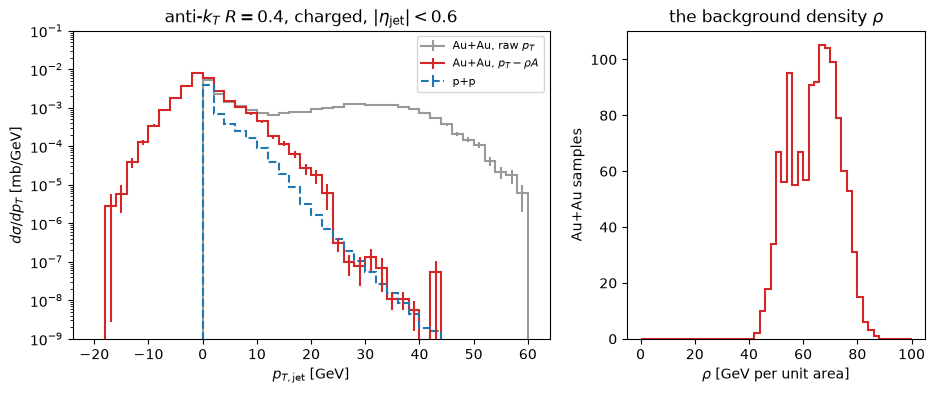

In [22]:
import matplotlib.pyplot as plt
import mplhep as mh

if FASTJET:
    jets = {}
    for s in ["auau", "pp"]:
        with uproot.open(OUT / f"jets_{s}.root") as rf:
            jets[s] = {k: rf[k].to_hist() for k in ["h_raw", "h_sub", "h_rho"]}
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.6, 1]})
    mh.histplot(jets["auau"]["h_raw"], ax=ax, label=r"Au+Au, raw $p_T$", flow="none", color="0.6")
    mh.histplot(jets["auau"]["h_sub"], ax=ax, label=r"Au+Au, $p_T - \rho A$", flow="none", color="C3")
    mh.histplot(jets["pp"]["h_sub"], ax=ax, label="p+p", flow="none", color="C0", ls="--")
    ax.set(yscale="log", ylim=(1e-9, 0.1), xlabel=r"$p_{T,\mathrm{jet}}$ [GeV]",
           ylabel=r"$d\sigma/dp_T$ [mb/GeV]", title=r"anti-$k_T$ $R=0.4$, charged, $|\eta_\mathrm{jet}|<0.6$")
    ax.legend(fontsize=8)
    rho = jets["auau"]["h_rho"]
    mh.histplot(rho, ax=bx, flow="none", color="C3", yerr=False)
    c = rho.axes[0].centers
    mean_rho = (rho.values() * c).sum() / rho.values().sum()
    sd_rho = np.sqrt((rho.values() * (c - mean_rho) ** 2).sum() / rho.values().sum())
    bx.set(xlabel=r"$\rho$ [GeV per unit area]", ylabel="Au+Au samples", title=r"the background density $\rho$")
    print(f"rho = {mean_rho:.0f} +- {sd_rho:.0f} GeV per unit area")
    sub, pp = jets["auau"]["h_sub"], jets["pp"]["h_sub"]
    e = sub.axes[0].edges
    for lo, hi in [(10, 20), (20, 24), (24, 40)]:
        b = (e[:-1] >= lo) & (e[1:] <= hi)
        print(f"jets at {lo}-{hi} GeV: Au+Au / p+p = {sub.values()[b].sum() / pp.values()[b].sum():.2f}"
              f"  ({int((jets['auau']['h_sub'].values()[b] > 0).sum())} non-empty Au+Au bins)")

**What to notice.**

- **The background:** $\rho \approx 64$ GeV per unit area, with a spread of about ±9 from
  sample to sample. A jet of $R = 0.4$ ($A \approx \pi R^2 \approx 0.5$) collects about 32 GeV
  of it. The raw Au+Au spectrum (grey) is therefore mostly the background: a broad bump
  around 30 GeV, although most of these jets come from p̂T of 10–20 GeV.
- **After the subtraction** the Au+Au jets spread around zero, from $-18$ to beyond $+20$ GeV.
  $\rho$ is a median over the whole event; a single cone holds more or less than that, so
  the subtracted $p_T$ of a jet is smeared by these region-to-region fluctuations. Most of these
  "jets" are combinatorial: a cone of background hadrons, not a jet from the hard scattering.
- **Below about 24 GeV the Au+Au spectrum is 5–10 times above p+p,** made by those
  fluctuations, not by jets. Above 24 GeV the two are close (Au+Au/p+p = 0.9 over 24–40 GeV),
  but with 40 events per window and errors of 40–80 % per bin, these Au+Au events are too few
  to measure how much the jets are suppressed. Measurements handle
  this with a higher jet $p_T$ threshold, unfolding of the fluctuations, and jets embedded into
  the background to measure them. Tutorial 08 (Python) does this with FastJet.

## 8. Pitfalls

| symptom | cause, fix |
|---|---|
| ROOT can't read an RNTuple (`not a TTree`, unknown class) | ROOT < 6.34: install a newer ROOT, or convert with `run_h5toROOT.py --format ttree` |
| `use of undeclared identifier 'v1'`, `no template named 'unordered_set'` (macOS) | a file `VERSION` in the folder ROOT runs in (this tutorial folder has one): macOS file names ignore case, so it hides the C++ header `<version>`. Run ROOT in another folder, as `root()` does |
| `'assert.h' file not found` when ACLiC compiles | conda's ROOT outside its environment: `conda activate` the ROOT environment first |
| `fastjet/ClusterSequenceArea.hh: No such file` | add FastJet's include directory (`fastjet-config --prefix`/include), or install `fastjet-cxx` |
| `undefined symbol` / `fastjet::...` when the macro loads | load `libfastjet` and `libfastjettools` before the `.C+` call |
| `Error: You can only make one query at a time` | `fastjet-config --cxxflags --libs`: call it twice, once per query |
| a stale result after editing a header | `.C+` recompiles when the macro or its headers change; force it with `.C++`, or delete the `*_C.so` |
| ACLiC files in `git status` | `*_C.so`, `*_C.d`, `*.pcm` are git-ignored in js-contrib; elsewhere add them to your `.gitignore` |
| `std::runtime_error ... has no bg_unit` | `bkg()` on a vacuum (p+p) file: check `info.vacuum` |
| ROOT's C++ notebook kernel dies at the start | `pip install metakernel` in the ROOT environment; deactivate other venvs first |
| errors too small for the background | a background shared by several events, filled once per event: fill it once with the summed weight (`spectra.C`) |

More in [ROOT and C++, section 7](https://jhputschke.github.io/js-contrib/analysis/root/#7-troubleshooting).

### Check your result

In [23]:
exp = json.load(open("expected/10_root_cpp_macros.json"))
for name, ref in exp["integrals_mb"].items():
    h = h_cpp[name]
    np.testing.assert_allclose((h.values() * np.diff(h.axes[0].edges)).sum(), ref, rtol=1e-6)
np.testing.assert_allclose(h_cpp["h_frag"].values(), py09, rtol=1e-9)        # = tutorial 09
if FASTJET:
    np.testing.assert_allclose(mean_rho, exp["mean_rho"], rtol=1e-6)
    np.testing.assert_allclose(jets["pp"]["h_sub"].values(), exp["jets_pp"], rtol=1e-6)
    np.testing.assert_allclose(jets["auau"]["h_sub"].values(), exp["jets_auau_sub"], rtol=1e-6)
print("All checks pass.")

All checks pass.


## Exercises

1. **Per event instead of mb.** Run `spectra.C` with `xsec = false` (third argument). What
   is the mean number of charged hadrons at $|\eta| < 1$ per event, and how does it compare
   with tutorial 09's per-sample average?
2. **The wake in C++.** Add `h_wake = h_bkgdep − h_bkg` to `spectra.C`, per event. What is its
   integral, and how large is its error? Why is the background filled once per background, not
   once per event, and what happens to the error if you change that?
3. **Jets of $R = 0.2$.** Run `jets.C` with `R = 0.2`. How do $\rho A$ and the spread of the
   subtracted spectrum around zero change? From which $p_T$ on does Au+Au fall below p+p?
4. **A compiled program.** Write a `main()` that calls `spectra(...)` and compile it with
   `g++ -O2 -std=c++17 -Iout/10_root_cpp main.cxx $(root-config --cflags --libs) -lROOTNTuple`
   (see [ROOT and C++](https://jhputschke.github.io/js-contrib/analysis/root/#5-fastjet-in-c)). Is it faster than ACLiC?

## Next steps

- Everything about the ROOT files, the reader and the macros: [ROOT and C++](https://jhputschke.github.io/js-contrib/analysis/root/) and `analysis_root/README.md` in js-contrib.
- Jets in Python, with embedding and the p+p reference: tutorial 08 and [Jets with FastJet](https://jhputschke.github.io/js-contrib/analysis/jets/).
- The same files from Python, with uproot: tutorial 09.
- The C++ map steps of the Z+jet analyses (FastJet, ρA, embedding): [ROOT and C++, section 6](https://jhputschke.github.io/js-contrib/analysis/root/#6-the-zjet-analyses-in-c).